<a href="https://colab.research.google.com/github/TanzilaDewan789/Machine_Learning/blob/main/3.Outlier_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Feature Engineeirng Outlier detection
1. normal distributions
2. factor that change normal distribution
3. empirical rule (68-97-99 Rule)
4. Z- Score
5. IQR

#Normal Distribution of data (Average of data)
Characteristics of Normal Distribution
1. Bell-shaped: The curve looks like a bell(bell curve).
2. Symmetrical: Both sides of the curve are approximately identical.
3. Mean = Median = Mode: All three have the same value at the center.
4. Most values are near the mean: Fewer values are found far away from the mean.

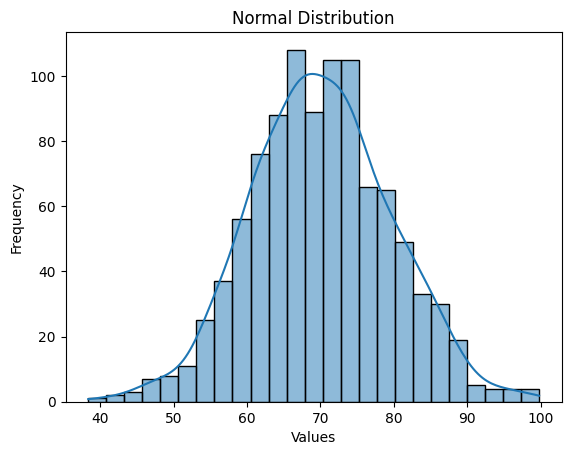

In [5]:
#code is using just for understand graphical representaion
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Generate normally distributed data
data = np.random.normal(loc=70, scale=10, size=1000)#avg, std, values

# Plot
sns.histplot(data, kde=True)

plt.title('Normal Distribution')
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.show()

# Factors That Change Normal Distribution

## 1. Mean
Mean determines the center/position of the curve.

Formula:
$$
\mu = \frac{x_1+x_2+x_3+\cdots+x_N}{N}
$$
Where:
- $\mu$ = Mean
- $x_i$ = Each data value
- $N$ = Total number of values
- $\sum$ = Sum of all values

Example:
$$
\mu = \frac{10+20+30}{3} = 20
$$

## 2. Standard Deviation (STD)
STD determines the spread/width of the curve.(How much far/ spread from the mean both side)

Formula:
$$
\sigma = \sqrt{\frac{\sum_{i=1}^{N}(x_i-\mu)^2}{N}}
$$
Where:
- $\sigma$ = Standard Deviation
- $x_i$ = Each data value
- $\mu$ = Mean
- $N$ = Total number of values
- $\sum$ = Sum of all values
Example:
$$
\sigma = \sqrt{\frac{(10-20)^2+(20-20)^2+(30-20)^2}{3}}
$$

$$
\sigma = 8.16
$$

#Empirical rule of niormal distribution (68-95-99.7 Rule)

The Empirical Rule explains how data is distributed in a normal distribution based on its mean (μ) and standard deviation (σ).


Identify potential outliers in normal data

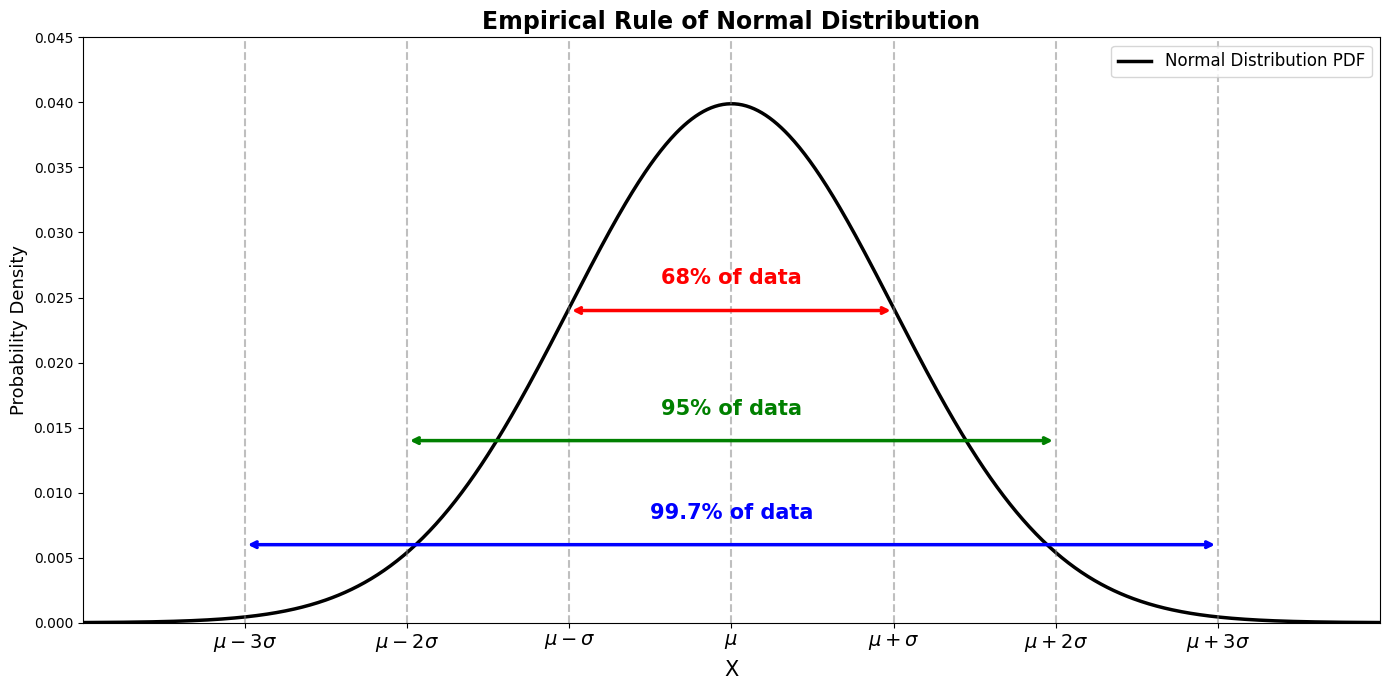

In [6]:
#code is using just for understand graphical representaion

from scipy.stats import norm

# 1. Mean and Standard Deviation
mu = 50
sigma = 10

# 2. Generate normal distribution
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y = norm.pdf(x, mu, sigma)

# 3. Create figure
plt.figure(figsize=(14, 7))

# 4. Plot normal distribution curve
plt.plot(x, y, color='black', linewidth=2.5,
         label='Normal Distribution PDF')

# 5. Draw vertical sigma lines
for i in range(-3, 4):
    plt.axvline(
        mu + i*sigma,
        color='gray',
        linestyle='--',
        alpha=0.5
    )

# 6. Add percentage arrows

# 68%: mu - sigma to mu + sigma
plt.annotate(
    '', xy=(mu + sigma, 0.024),
    xytext=(mu - sigma, 0.024),
    arrowprops=dict(arrowstyle='<->', color='red', lw=2.5)
)

plt.text(mu, 0.026, '68% of data',
         color='red', fontsize=15,
         ha='center', fontweight='bold')


# 95%: mu - 2sigma to mu + 2sigma
plt.annotate(
    '', xy=(mu + 2*sigma, 0.014),
    xytext=(mu - 2*sigma, 0.014),
    arrowprops=dict(arrowstyle='<->', color='green', lw=2.5)
)

plt.text(mu, 0.016, '95% of data',
         color='green', fontsize=15,
         ha='center', fontweight='bold')


# 99.7%: mu - 3sigma to mu + 3sigma
plt.annotate(
    '', xy=(mu + 3*sigma, 0.006),
    xytext=(mu - 3*sigma, 0.006),
    arrowprops=dict(arrowstyle='<->', color='blue', lw=2.5)
)

plt.text(mu, 0.008, '99.7% of data',
         color='blue', fontsize=15,
         ha='center', fontweight='bold')


# 7. X-axis labels
labels = [
    r'$\mu-3\sigma$',
    r'$\mu-2\sigma$',
    r'$\mu-\sigma$',
    r'$\mu$',
    r'$\mu+\sigma$',
    r'$\mu+2\sigma$',
    r'$\mu+3\sigma$'
]

positions = [mu + i*sigma for i in range(-3, 4)]

plt.xticks(positions, labels, fontsize=14)

# 8. Titles and axis labels
plt.title('Empirical Rule of Normal Distribution',
          fontsize=17, fontweight='bold')

plt.xlabel('X', fontsize=15)
plt.ylabel('Probability Density', fontsize=13)

# 9. Formatting
plt.xlim(mu - 4*sigma, mu + 4*sigma)
plt.ylim(0, 0.045)

plt.legend(fontsize=12, loc='upper right')
plt.grid(False)

plt.tight_layout()
plt.show()



# Z-Score

**Z-score** tells us how far a data point is from the mean (average), measured in terms of standard deviations.

In simple words, it tells us whether a value is:

- Above the mean.
- Below the mean.
- Equal to the mean.

### 1. Formula
if the data is far from 1 sigma, then z= 1, datapoint = x

mu + 1*sigma = x

mu + z*sigma = x

z = x- mu/sigma

$$
z = \frac{x-\mu}{\sigma}
$$

| Symbol | Meaning |
|:---:|---|
| $x$ | Individual data value |
| $\mu$ | Mean (average) |
| $\sigma$ | Standard deviation |
| $z$ | Z-score |

### 2. Example

Suppose:

- Mean ($\mu$) = 50
- Standard deviation ($\sigma$) = 10
- Individual value ($x$) = 70

$$
z = \frac{70-50}{10} = 2
$$

**Result: Z-score = +2**

This means 70 is 2 standard deviations above the mean.

### 3. How to Interpret Z-score

| Z-score | Meaning |
|:---:|---|
| 0 | Exactly at the mean |
| +1 | 1 SD above the mean |
| +2 | 2 SD above the mean |
| +3 | 3 SD above the mean |
| -1 | 1 SD below the mean |
| -2 | 2 SD below the mean |
| -3 | 3 SD below the mean |

### 4. Why Do We Use Z-score?

One important use is **outlier detection**.

- Z-score between -3 and +3: Generally considered within 3 standard deviations.
- Z-score below -3 or above +3: Potential outlier. (Because 99.7% data are within 3singma)

**Note:** The ±3 rule is a common guideline, not a guarantee that a value is an outlier.



## Question: Z-score Calculation and Outlier Detection

A student obtained 80 marks in English and 70 marks in Mathematics. The average marks and standard deviations for both subjects are given below:

| Subject | Student Marks | Mean | Standard Deviation |
|:---:|:---:|:---:|:---:|
| English | 80 | 75 | 5 |
| Mathematics | 70 | 60 | 5 |

### Perform the following tasks:

1. Calculate the Z-score manually for each subject using the Z-score formula.
2. Identify potential outliers using the ±3 Z-score threshold.
3. Print the Z-scores and potential outlier values.

**Hint:**

Use NumPy arrays and the following formula:

$$
z = \frac{x-\mu}{\sigma}
$$


#Manual calculation

In [12]:

# Student marks
data = np.array([80, 70])

# Mean and standard deviation
mean = np.array([75, 60])
std = np.array([5, 5])

# 1. Calculate Z-score manually
z_score = (data - mean) / std

print("Z-scores:", z_score)

# 2. Identify potential outliers using Z-score
outliers = data[np.abs(z_score) > 3]

print("Potential Outliers:", outliers)

Z-scores: [1. 2.]
Potential Outliers: []


#Visualization 1

In [13]:
import plotly.graph_objects as go

# Data
subjects = ['English', 'Math']
marks = [80, 70]
mean = [75, 60]
std = [5, 5]

# Calculate Z-score manually
z_score = [(x - mu) / sigma for x, mu, sigma in zip(marks, mean, std)]

# Identify potential outliers
outliers = [abs(z) > 3 for z in z_score]

# Create DataFrame
import pandas as pd

df = pd.DataFrame({
    'Subject': subjects,
    'Marks': marks,
    'Mean': mean,
    'SD': std,
    'Z-score': z_score,
    'Potential Outlier': outliers
})

print(df)

# Plotly visualization
fig = go.Figure()

fig.add_trace(go.Bar(
    x=subjects,
    y=z_score,
    text=z_score,
    textposition='outside',
    name='Z-score'
))

# Outlier threshold lines
fig.add_hline(y=3, line_dash='dash',
              annotation_text='+3 (Upper Threshold)')

fig.add_hline(y=-3, line_dash='dash',
              annotation_text='-3 (Lower Threshold)')

fig.add_hline(y=0, line_dash='solid',
              annotation_text='Mean (0)')

fig.update_layout(
    title='Z-score Comparison: English vs Math',
    xaxis_title='Subjects',
    yaxis_title='Z-score',
    yaxis=dict(range=[-4, 4]),
    template='plotly_white'
)

fig.show()

   Subject  Marks  Mean  SD  Z-score  Potential Outlier
0  English     80    75   5      1.0              False
1     Math     70    60   5      2.0              False


# Visualization 2, KDE

In [16]:
import numpy as np
import pandas as pd
import plotly.express as px

# Data
subjects = ['English', 'Math']
marks = [80, 70]
mean = [75, 60]
std = [5, 5]

# Calculate Z-score manually
z_score = [(x - mu) / sigma for x, mu, sigma in zip(marks, mean, std)]

# Identify potential outliers
outliers = [abs(z) > 3 for z in z_score]

# Create DataFrame
df = pd.DataFrame({
    'Subject': subjects,
    'Marks': marks,
    'Mean': mean,
    'SD': std,
    'Z-score': z_score,
    'Potential Outlier': outliers
})

print(df)

# KDE plot using Plotly
from scipy.stats import gaussian_kde

# Generate smooth KDE curve
x = np.linspace(-4, 4, 300)
kde = gaussian_kde(z_score)

density = kde(x)

fig = px.area(
    x=x,
    y=density,
    title='KDE Plot of Z-scores'
)

# Outlier threshold lines
fig.add_vline(x=3, line_dash='dash',
              annotation_text='+3 Upper Threshold')

fig.add_vline(x=-3, line_dash='dash',
              annotation_text='-3 Lower Threshold')

# Add individual Z-score positions
fig.add_scatter(
    x=z_score,
    y=[0, 0],
    mode='markers+text',
    text=subjects,
    textposition='top center',
    name='Z-scores'
)

fig.update_layout(
    xaxis_title='Z-score',
    yaxis_title='Density',
    template='plotly_white'
)

fig.show()

   Subject  Marks  Mean  SD  Z-score  Potential Outlier
0  English     80    75   5      1.0              False
1     Math     70    60   5      2.0              False


# IQR - Inter Quartile Range

IQR (Interquartile Range) measures the spread of the middle 50% of a dataset.


### 1. Formula

$$
IQR = Q3 - Q1
$$

| Symbol | Meaning |
|:---:|---|
| Q1 | First Quartile (25th percentile) |
| Q2 | Second Quartile (50th percentile / Median) |
| Q3 | Third Quartile (75th percentile) |
| IQR | Interquartile Range |


marks = 12,45,67,68,70,72,73,75,76,80,81,82,84,91,100

1. 50 percentile, Q2 = 75 (Median)
2. 25 percentile, Q1 = 68 (Lower percentile)
3. 75 percentile ,Q3 = 82 (Upper percentile)

**Outlier boundaries (IQR method):**


### 2. Calculate Outlier Boundaries

**Lower Bound:**

$$
Q1 - (1.5 \times IQR)
$$

$$
69 - (1.5 \times 12.5) = 50.25
$$

**Upper Bound:**

$$
Q3 + (1.5 \times IQR)
$$

$$
81.5 + (1.5 \times 12.5) = 100.25
$$

**Conclusion:**
- Values less than 50.25 = Potential Outliers
- Values greater than 100.25 = Potential Outliers






In [17]:
import numpy as np

marks = [12,45,67,68,70,72,73,75,76,80,81,82,84,91,100]

Q1 = np.percentile(marks, 25)
Q3 = np.percentile(marks, 75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)# approx - 14

Q1: 69.0
Q3: 81.5
IQR: 12.5


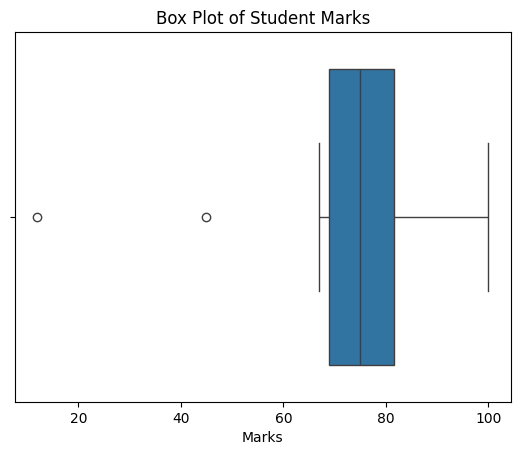

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

marks = [12, 45, 67, 68, 70, 72, 73, 75, 76, 80, 81, 82, 84, 91, 100]

sns.boxplot(x=marks)

plt.title("Box Plot of Student Marks")
plt.xlabel("Marks")
plt.show()

#Part 2 is on the way InShaAllah...